<a href="https://colab.research.google.com/github/asmipandey18/Elevvo_Ml_Internship/blob/main/task4_loan_approval_prediction/Loan_approval_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import pandas as pd

In [32]:
df = pd.read_csv("/content/loan_approval_dataset.csv")

In [33]:
df.shape

(4269, 13)

In [34]:
df.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


In [35]:
df.columns.tolist()

['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

In [36]:
df.columns = df.columns.str.strip()
df = df.drop(columns=["loan_id"])
df.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status'],
      dtype='object')

In [37]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          4269 non-null   int64 
 1   education                 4269 non-null   object
 2   self_employed             4269 non-null   object
 3   income_annum              4269 non-null   int64 
 4   loan_amount               4269 non-null   int64 
 5   loan_term                 4269 non-null   int64 
 6   cibil_score               4269 non-null   int64 
 7   residential_assets_value  4269 non-null   int64 
 8   commercial_assets_value   4269 non-null   int64 
 9   luxury_assets_value       4269 non-null   int64 
 10  bank_asset_value          4269 non-null   int64 
 11  loan_status               4269 non-null   object
dtypes: int64(9), object(3)
memory usage: 400.3+ KB


In [38]:
df.isnull().sum()

,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0
luxury_assets_value,0


In [39]:
df.duplicated().sum()

np.int64(0)

In [40]:
df["loan_status"].value_counts()

,count
loan_status,
Approved,2656
Rejected,1613


In [41]:
df["loan_status"].value_counts(normalize=True).round(3)

,proportion
loan_status,
Approved,0.622
Rejected,0.378


In [42]:
df["education"].unique(), df["self_employed"].unique(), df["loan_status"].unique()

(array(['Graduate', 'Not Graduate'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['Approved', 'Rejected'], dtype=object))

In [43]:
df["education"] = df["education"].map({"Graduate": 1, "Not Graduate": 0})
df["self_employed"] = df["self_employed"].map({"Yes": 1, "No": 0})
df["loan_status"] = df["loan_status"].map({"Approved": 1, "Rejected": 0})
df.head(10)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0
5,0,1,1,4800000,13500000,10,319,6800000,8300000,13700000,5100000,0
6,5,1,0,8700000,33000000,4,678,22500000,14800000,29200000,4300000,1
7,2,1,1,5700000,15000000,20,382,13200000,5700000,11800000,6000000,0
8,0,1,1,800000,2200000,20,782,1300000,800000,2800000,600000,1
9,5,0,0,1100000,4300000,10,388,3200000,1400000,3300000,1600000,0


In [44]:
print(df.isnull().sum())
print(df["loan_status"].value_counts())
print(df["loan_status"].value_counts(normalize=True).round(3))
print("Duplicates:", df.duplicated().sum())

no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64
loan_status
1    2656
0    1613
Name: count, dtype: int64
loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64
Duplicates: 0


## Exploring the data first (EDA)

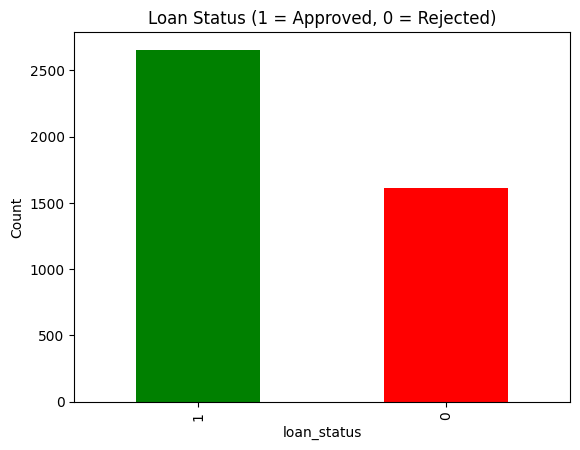

loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64


In [45]:
## Class balance (the most important plot for this task)
import matplotlib.pyplot as plt
import seaborn as sns

df["loan_status"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Loan Status (1 = Approved, 0 = Rejected)")
plt.xlabel("loan_status")
plt.ylabel("Count")
plt.show()
print(df["loan_status"].value_counts(normalize=True).round(3))

### Observation: Class Balance
The data is mildly imbalanced (62.2% Approved, 37.8% Rejected). Since accuracy can hide poor performance on the minority class, I will focus on precision, recall and F1-score, and test imbalance techniques like SMOTE.

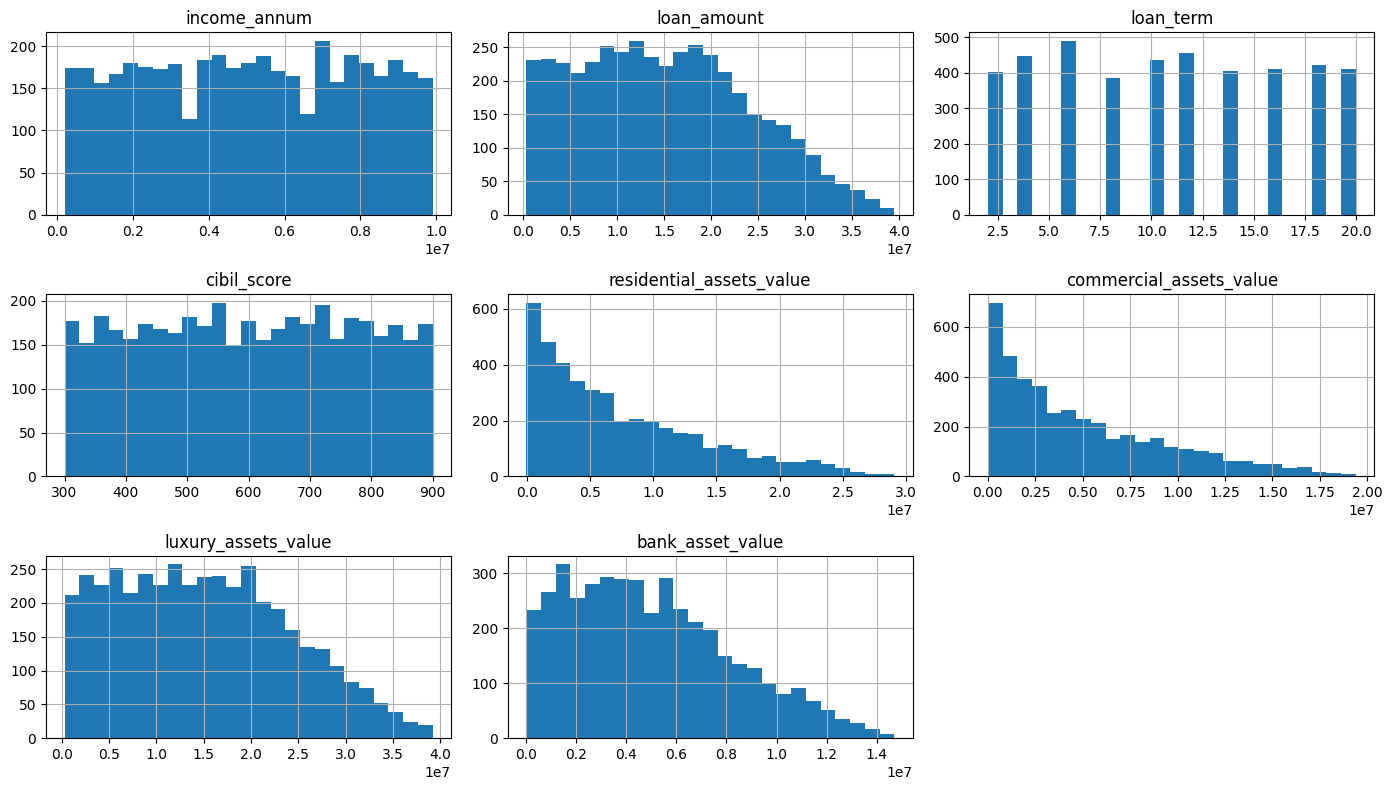

In [46]:
## Distribution of the numeric columns
num_cols = ["income_annum", "loan_amount", "loan_term", "cibil_score",
            "residential_assets_value", "commercial_assets_value",
            "luxury_assets_value", "bank_asset_value"]
df[num_cols].hist(bins=25, figsize=(14, 8))
plt.tight_layout()
plt.show()

### Observation: Distribution of Numerical Features
income_annum and cibil_score are spread fairly evenly. The asset columns are right-skewed (many low values, a few very high). The features are on very different scales, so I will scale them for Logistic Regression.

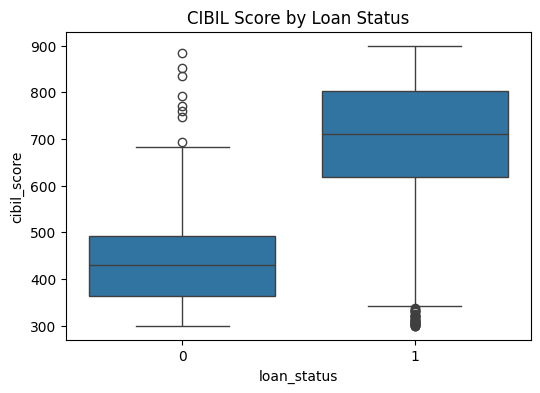

In [47]:
## How the credit score relates to approval
plt.figure(figsize=(6, 4))
sns.boxplot(x="loan_status", y="cibil_score", data=df)
plt.title("CIBIL Score by Loan Status")
plt.show()

### Observation: CIBIL Score
Approved applicants have much higher CIBIL scores (median about 710) than rejected ones (median about 430), and the two boxes barely overlap, so credit score is a strong predictor of approval. A few outliers exist, such as rejected applicants with high scores and approved applicants with very low ones. All values are within the valid 300 to 900 range, so I kept them. These cases also suggest that other factors, not only credit score, affect the decision.

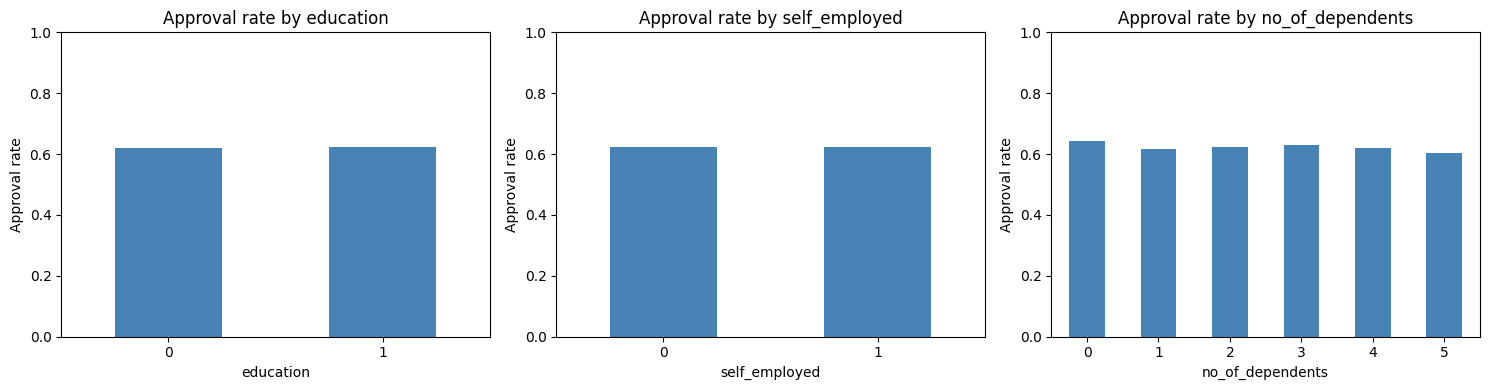

In [48]:
## Approval rate by education, self-employment, and dependents
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["education", "self_employed", "no_of_dependents"]):
    df.groupby(col)["loan_status"].mean().plot(kind="bar", ax=a, color="steelblue")
    a.set_title(f"Approval rate by {col}")
    a.set_ylabel("Approval rate")
    a.set_ylim(0, 1)
    a.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Observation: Education, Self-Employment, Dependents

The approval rate is almost the same (around 62%) across education level, self-employment status, and number of dependents. These features have little effect on approval, unlike credit score.

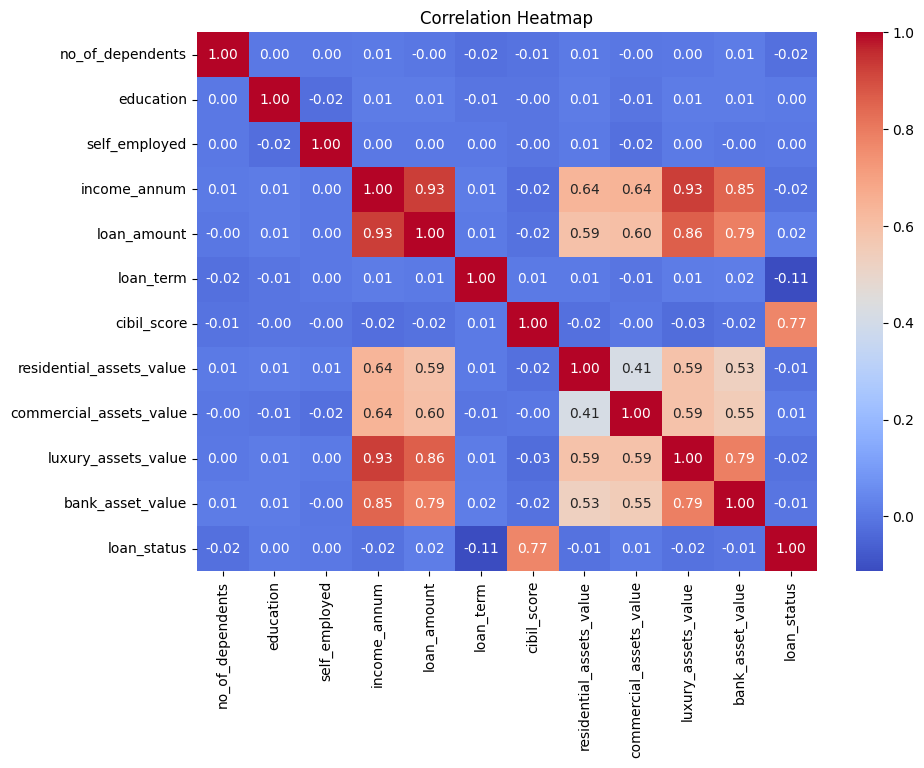

In [49]:
## Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Observation: Correlation Heatmap

cibil_score has by far the strongest correlation with loan_status (0.77). All other features are close to zero, so they have little linear relationship with approval. Income, loan amount and the asset columns are strongly correlated with each other (for example income and loan amount at 0.93), which is called multicollinearity.

## Train-Test split.

In [50]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["loan_status"])
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [51]:
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(3))

Train: (3415, 11) | Test: (854, 11)
Train class balance:
 loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64
Test class balance:
 loan_status
1    0.622
0    0.378
Name: proportion, dtype: float64


### Observation: Train-Test Split

The data was split 80/20 into 3,415 training rows and 854 test rows. Using stratify kept the class balance identical in both sets (62.2% Approved, 37.8% Rejected), so the test set is a fair sample of the original data.

## Model Training
## Logistic Regression

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## Evaluation: Logistic Regression

              precision    recall  f1-score   support

    Rejected       0.90      0.87      0.88       323
    Approved       0.92      0.94      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.90      0.91       854
weighted avg       0.91      0.91      0.91       854



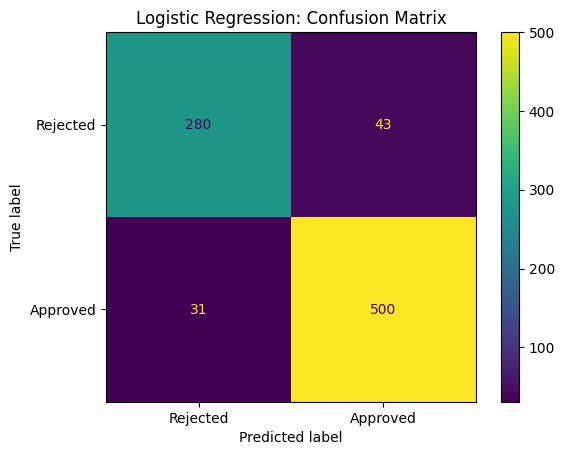

In [53]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(classification_report(y_test, y_pred, target_names=["Rejected", "Approved"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Rejected", "Approved"])
plt.title("Logistic Regression: Confusion Matrix")
plt.show()

### Observation: Logistic Regression

Logistic Regression reached 91% accuracy, well above the 62% baseline of always predicting “Approved.” Performance is strong for both classes (F1 of 0.93 for Approved and 0.88 for Rejected), but slightly lower for the minority Rejected class. The model wrongly approved 43 loans that should have been rejected and wrongly rejected 31 loans that should have been approved.

## Decision Tree

In [54]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

## Evaluation: Decision Tree

              precision    recall  f1-score   support

    Rejected       0.98      0.98      0.98       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



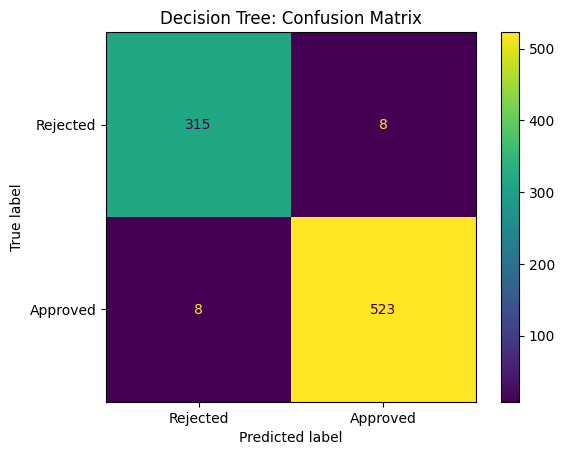

In [55]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(classification_report(y_test, y_pred_tree, target_names=["Rejected", "Approved"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tree, display_labels=["Rejected", "Approved"])
plt.title("Decision Tree: Confusion Matrix")
plt.show()

### Observation: Decision Tree

The Decision Tree reached 98% accuracy, with precision, recall and F1 of 0.98 for both classes, and only 16 wrong predictions out of 854 (8 of each kind). It clearly outperformed Logistic Regression (91%), possibly because loan approval follows threshold-like rules, such as on CIBIL score, that trees capture better than a linear model.

## Handling Class Imbalance (Bonus)

In [56]:
log_bal = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
log_bal.fit(X_train, y_train)
tree_bal = DecisionTreeClassifier(random_state=42, class_weight="balanced")
tree_bal.fit(X_train, y_train)

print("Logistic Regression (balanced)")
print(classification_report(y_test, log_bal.predict(X_test), target_names=["Rejected", "Approved"]))
print("Decision Tree (balanced)")
print(classification_report(y_test, tree_bal.predict(X_test), target_names=["Rejected", "Approved"]))

Logistic Regression (balanced)
              precision    recall  f1-score   support

    Rejected       0.88      0.93      0.90       323
    Approved       0.96      0.92      0.94       531

    accuracy                           0.92       854
   macro avg       0.92      0.92      0.92       854
weighted avg       0.93      0.92      0.92       854

Decision Tree (balanced)
              precision    recall  f1-score   support

    Rejected       0.97      0.96      0.97       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.97      0.98       854
weighted avg       0.98      0.98      0.98       854



### Observation: Class Weights

Using class_weight="balanced" improved Logistic Regression’s recall on the Rejected class from 0.87 to 0.93, with a small drop in precision (0.90 to 0.88), so it catches more risky loans at the cost of a few more false rejections. For the Decision Tree, it made no meaningful difference (accuracy stayed at 0.98), which suggests the tree already handled this mild imbalance well.

## SMOTE(Bonus)

In [57]:
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:\n", y_train.value_counts())
print("After SMOTE:\n", y_train_sm.value_counts())

log_sm = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_sm.fit(X_train_sm, y_train_sm)
tree_sm = DecisionTreeClassifier(random_state=42)
tree_sm.fit(X_train_sm, y_train_sm)

print("Logistic Regression (SMOTE)")
print(classification_report(y_test, log_sm.predict(X_test), target_names=["Rejected", "Approved"]))
print("Decision Tree (SMOTE)")
print(classification_report(y_test, tree_sm.predict(X_test), target_names=["Rejected", "Approved"]))

Before SMOTE:
 loan_status
1    2125
0    1290
Name: count, dtype: int64
After SMOTE:
 loan_status
1    2125
0    2125
Name: count, dtype: int64
Logistic Regression (SMOTE)
              precision    recall  f1-score   support

    Rejected       0.88      0.91      0.89       323
    Approved       0.94      0.92      0.93       531

    accuracy                           0.92       854
   macro avg       0.91      0.92      0.91       854
weighted avg       0.92      0.92      0.92       854

Decision Tree (SMOTE)
              precision    recall  f1-score   support

    Rejected       0.97      0.98      0.97       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



### Observation: SMOTE

SMOTE balanced the training set to 2,125 samples per class. For Logistic Regression it raised recall on the Rejected class from 0.87 to 0.91, with precision dropping slightly from 0.90 to 0.88, and overall accuracy rose from 0.91 to 0.92. For the Decision Tree there was no meaningful change (accuracy stayed at 0.98). Because the imbalance is mild (62/38), both SMOTE and class weights gave only small gains, and class weights worked about as well as SMOTE for Logistic Regression.

## Model Comparison

In [58]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

preds = {
    "Logistic Regression": y_pred,
    "LR + Class Weights": log_bal.predict(X_test),
    "LR + SMOTE": log_sm.predict(X_test),
    "Decision Tree": y_pred_tree,
    "Tree + Class Weights": tree_bal.predict(X_test),
    "Tree + SMOTE": tree_sm.predict(X_test),
}

rows = []
for name, p in preds.items():
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, p, labels=[0], zero_division=0)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Rejected Precision": prec[0],
                 "Rejected Recall": rec[0],
                 "Rejected F1": f1[0]})

comparison = pd.DataFrame(rows).round(3)
comparison

,Model,Accuracy,Rejected Precision,Rejected Recall,Rejected F1
0,Logistic Regression,0.913,0.900,0.867,0.883
1,LR + Class Weights,0.924,0.877,0.929,0.902
2,LR + SMOTE,0.919,0.880,0.910,0.895
3,Decision Tree,0.981,0.975,0.975,0.975
4,Tree + Class Weights,0.977,0.975,0.963,0.969
5,Tree + SMOTE,0.980,0.972,0.975,0.974


### Observation: Model Comparison

The plain Decision Tree performed best (accuracy 0.981, Rejected F1 0.975). Class weights and SMOTE improved Logistic Regression’s recall on the Rejected class (from 0.867 to 0.929 and 0.910) with a small loss in precision, but they did not change the Decision Tree meaningfully. This is likely because the imbalance is mild (62/38) and the tree already separates the classes well.

In [59]:
print("Train accuracy:", accuracy_score(y_train, tree_model.predict(X_train)))
print("Test accuracy :", accuracy_score(y_test, y_pred_tree))

Train accuracy: 1.0
Test accuracy : 0.9812646370023419


### Observation: Overfitting Check

The Decision Tree reached 100% training accuracy and 98.1% test accuracy. The small gap suggests mild overfitting, but the high test score on unseen data shows the model still generalizes well.

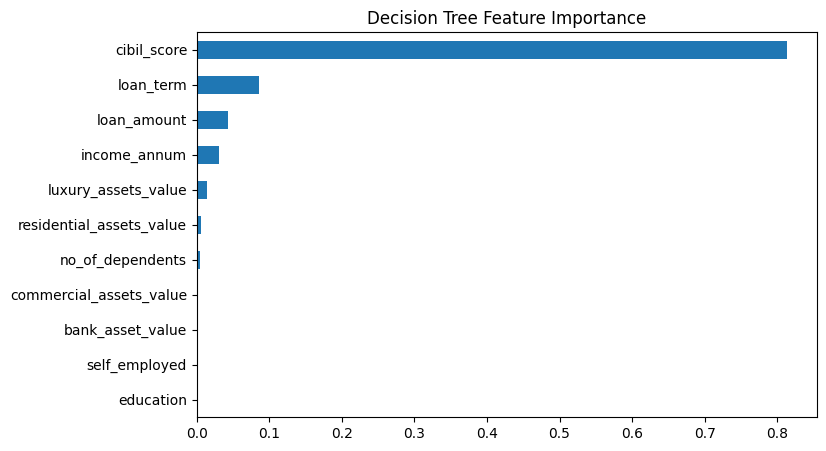

In [60]:
importances = pd.Series(tree_model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 5), title="Decision Tree Feature Importance")
plt.show()

### Observation: Feature Importance

CIBIL score is by far the most important feature (about 0.81), followed by loan term, loan amount and income. Education, self-employment and most asset columns contribute almost nothing. This agrees with the EDA, where only CIBIL score clearly separated approved from rejected applicants.

## Conclusion
The dataset is mildly imbalanced (62% Approved, 38% Rejected), so I evaluated models using precision, recall and F1 and not accuracy alone. The Decision Tree performed best (98% accuracy, F1 of 0.98 for both classes) and clearly outperformed Logistic Regression (91%). Class weights and SMOTE raised Logistic Regression’s recall on the Rejected class (from 0.87 to 0.93 and 0.91) but made no meaningful difference to the tree. CIBIL score was the dominant predictor in both the EDA and the model. Limitations: the imbalance is mild, so the effect of SMOTE is hard to judge, the tree shows mild overfitting (train 100% vs test 98.1%), and I used a single train/test split. Future work could add cross-validation, limit tree depth, and try ensemble models like Random Forest.